QUESTÃO 1 - EXPLORAÇÃO INICIAL
Quantidade de linhas: 50000
Quantidade de colunas: 15

Tipos de dados:
id_item_venda          int64
id_pedido              int64
data_venda               str
nome_produto             str
categoria_produto        str
quantidade             int64
preco_unitario       float64
desconto             float64
valor_total          float64
nome_cliente             str
cidade_cliente           str
estado_cliente           str
nome_vendedor            str
forma_pagamento          str
status_venda             str
dtype: object

Valores faltando em cada coluna:
id_item_venda          0
id_pedido              0
data_venda             0
nome_produto           0
categoria_produto      0
quantidade             0
preco_unitario         0
desconto               0
valor_total            0
nome_cliente           0
cidade_cliente       150
estado_cliente         0
nome_vendedor          0
forma_pagamento        0
status_venda           0
dtype: int64

Linhas duplicadas: 150

Ca

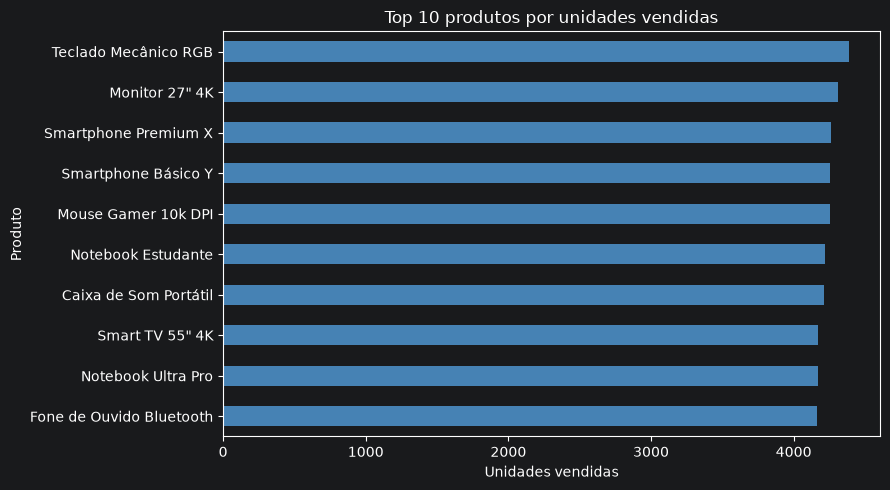

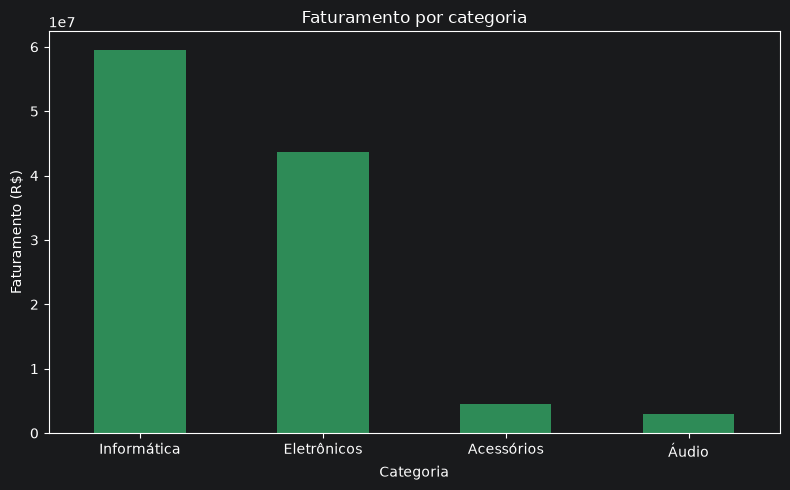

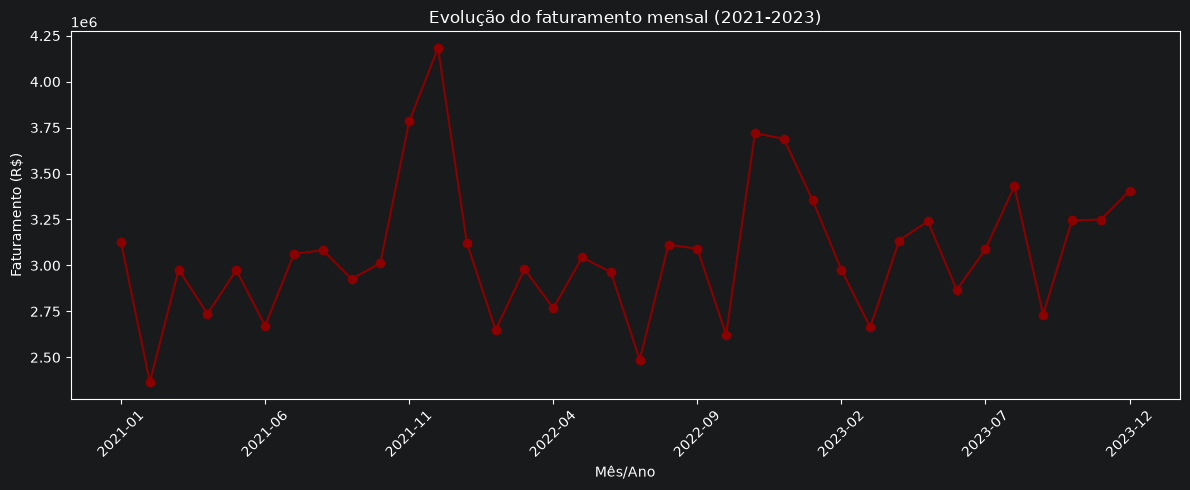

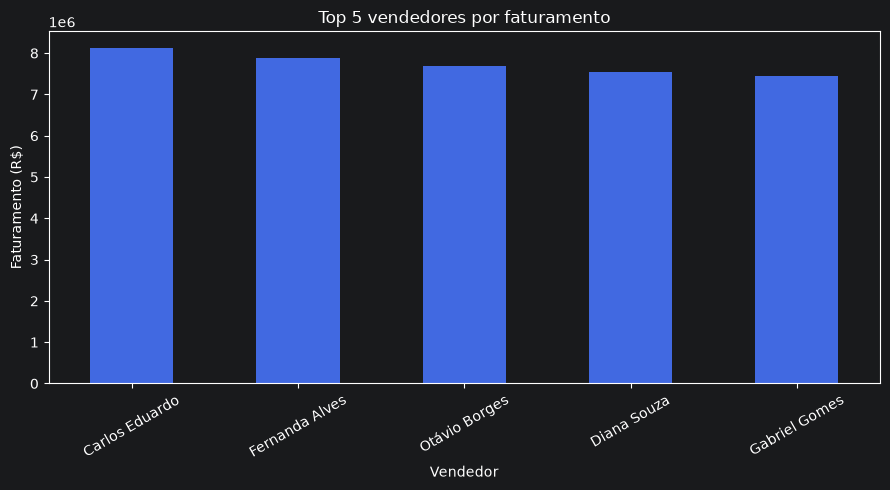

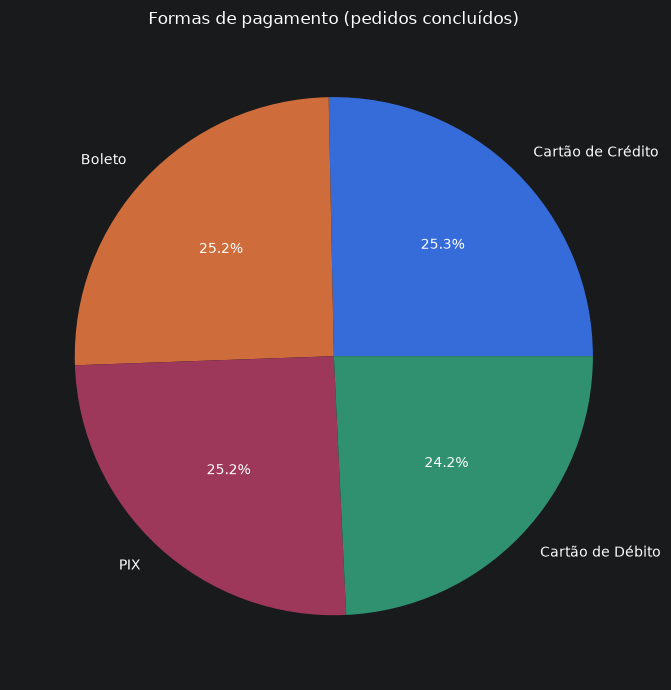

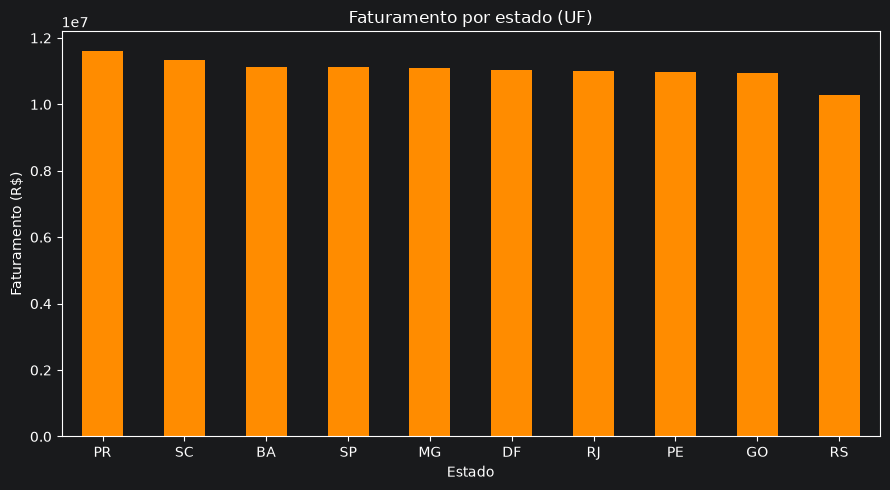

Os 6 gráficos foram salvos como arquivos PNG na pasta do projeto.
QUESTÃO 11 - ESTUDO APLICADO

PERGUNTA DE NEGÓCIO:
Em qual região e em qual categoria a empresa deve investir a maior parte
do orçamento de marketing do próximo trimestre?

COMO FOI FEITO:
Cruzamos três informações: região, categoria e ano. Comparamos o
faturamento de 2023 com o de 2021 para ver quem cresceu e quem caiu.
Também calculamos a taxa de perda (cancelados + devolvidos) de cada
combinação, para saber se o crescimento é saudável.

REGIÃO x CATEGORIA (do maior crescimento para o menor):
                                receita_2021  receita_2023  crescimento_%  taxa_perda_%
regiao       categoria_produto                                                         
Sudeste      Acessórios            413248.55     500289.68          21.06         10.72
Nordeste     Eletrônicos          2690187.84    3141696.48          16.78         12.12
Centro-Oeste Acessórios            268138.09     299000.17          11.51         

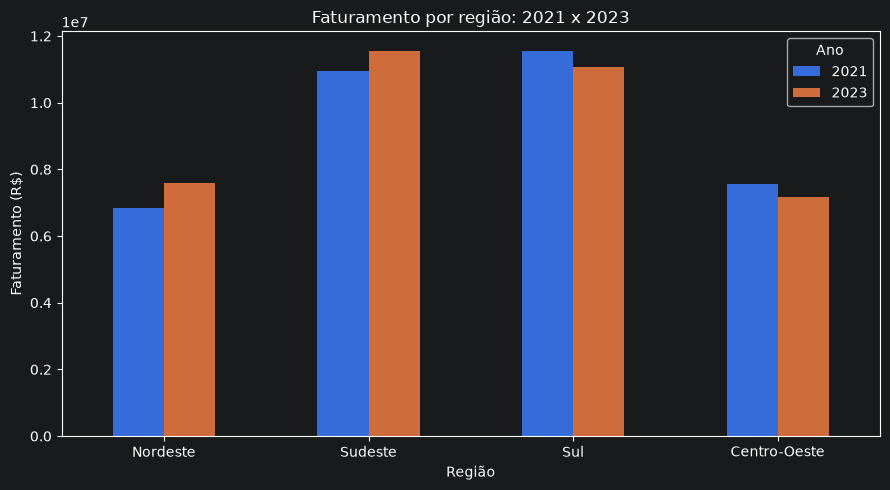


EXPLICAÇÃO:
O faturamento total parece parado, mas na verdade existem dois movimentos
opostos: Nordeste e Sudeste cresceram, enquanto Sul e Centro-Oeste
caíram. O crescimento do Nordeste vem principalmente de Eletrônicos, e o
Sudeste tem a maior venda de Informática da empresa. A taxa de perda é
parecida em todas as combinações (perto de 11%), então ela não impede
nenhum investimento.

CONCLUSÃO PARA A GESTOR:
Recomendamos colocar a maior parte do orçamento em duas frentes:
(1) Informática no Sudeste, que é a maior fonte de receita e continua
crescendo, com foco nos notebooks e oferecendo acessórios junto; e
(2) Eletrônicos no Nordeste, que é a combinação que mais cresce, com
foco em smartphones e Smart TV. Sul e Centro-Oeste devem manter o
orçamento atual e passar por uma análise de preço e concorrência antes
de receber mais dinheiro. Também sugerimos concentrar as propagandas em
novembro e dezembro, criar uma campanha em fevereiro (o mês mais fraco)
e incentivar o pagamento por PIX,

In [2]:
# PROJETO: ANÁLISE # PROJETO: ANÁLISE DE VENDAS (2021-2023)
import pandas as pd
import matplotlib.pyplot as plt


# transformar os valores no padrao do brasil
def dinheiro(valor):
    texto = f"R$ {valor:,.2f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return texto


# QUESTÃO 1 - EXPLORAÇÃO INICIAL
print("=" * 60)
print("QUESTÃO 1 - EXPLORAÇÃO INICIAL")
print("=" * 60)

df = pd.read_csv("vendas.csv", sep=";", encoding="utf-8")

print("Quantidade de linhas:", len(df))
print("Quantidade de colunas:", len(df.columns))
print("\nTipos de dados:")
print(df.dtypes)
print("\nValores faltando em cada coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("\nCategorias encontradas:")
print(df["categoria_produto"].unique())
print("\nStatus encontrados:")
print(df["status_venda"].unique())
print("\nEstados (UF) encontrados:")
print(df["estado_cliente"].unique())

print("""
EXPLICAÇÃO:
A base tem 50.000 linhas e 15 colunas. tem linhas repetiddas,
 cidades vazias, catgorias escritas da duas
formas diferentes (com e sem acento) e alguns valores errados
""")

# QUESTÃO 2 - TRATAMENTO DOS DADOS (LIMPEZA)

print("=" * 60)
print("QUESTÃO 2 - TRATAMENTO DOS DADOS")
print("=" * 60)

# Passo 1: tirar linhas duplicadas
antes = len(df)
df = df.drop_duplicates()
print("1) Duplicadas removidas:", antes - len(df))

# Passo 2: transformar datas e apagar as datas erradas
df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
antes = len(df)
df = df.dropna(subset=["data_venda"])
print("2) Datas inválidas removidas:", antes - len(df))

# Passo 3: existe algunas quantidades negativas e sao provavelmente erro de digitação
negativas = (df["quantidade"] < 0).sum()
df["quantidade"] = df["quantidade"].abs()
print("3) Quantidades negativas corrigidas:", negativas)

# Passo 4: tem alguns descontos maiores que o valor da produto, estas linhas foi apagadas
valor_bruto_item = df["quantidade"] * df["preco_unitario"]
antes = len(df)
df = df[df["desconto"] <= valor_bruto_item].copy()
print("4) Linhas com desconto maior que o valor bruto removidas:", antes - len(df))

# Passo 5: preencher cidade vazia (o estado continua válido)
vazias = df["cidade_cliente"].isna().sum()
df["cidade_cliente"] = df["cidade_cliente"].fillna("Não informada")
print("5) Cidades vazias preenchidas:", vazias)

# Passo 6: padronizacao das  nomes das categorias
correcao = {"Informatica": "Informática", "Eletronicos": "Eletrônicos"}
erradas = df["categoria_produto"].isin(["Informatica", "Eletronicos"]).sum()
df["categoria_produto"] = df["categoria_produto"].replace(correcao)
print("6) Categorias corrigidas:", erradas)

# Passo 7: calcular novamente os valores para garantir que estão certos (verificacao)
df["valor_bruto"] = df["quantidade"] * df["preco_unitario"]
df["valor_total"] = df["valor_bruto"] - df["desconto"]

# Passo 8: para mais facil controle, uma nova colunas foram lancadas e sao de apoio (região, ano e se o pedido foi perdido)
mapa_regioes = {
    "BA": "Nordeste", "PE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste",
    "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul"
}
df["regiao"] = df["estado_cliente"].map(mapa_regioes)
df["ano"] = df["data_venda"].dt.year
df["perdido"] = df["status_venda"].isin(["Cancelado", "Devolvido"])

# salvar a base limpa em um novo arquivo (vendas_tratado.csv)
df.to_csv("vendas_tratado.csv", sep=";", index=False, encoding="utf-8")

print("\nTotal de linhas depois da limpeza:", len(df))
print("Base limpa salva no arquivo vendas_tratado.csv")

print("""
EXPLICAÇÃO:
Sobrou menos de 1% de perda de dados, então a análise continua confiavel.
As quantidades negativas foram corrigidas ((ms não apagadas() porque o valor
total da linha provava que a quantidade era postiva. Já os descontos
maiores que o preco foram apagadas, porque não há como descobrir o valor
real da venda.
""")

# QUESTÃO 3 - FATURAMENTO TOTAL
print("=" * 60)
print("QUESTÃO 3 - FATURAMENTO TOTAL")
print("=" * 60)

# coloquei uma observacao: só venda "Concluído" é venda real.
# Cancelado e Devolvido nao sao reais. Pendente ainda não foi pago.
concluidas = df[df["status_venda"] == "Concluído"].copy()

faturamento_bruto = concluidas["valor_bruto"].sum()
total_descontos = concluidas["desconto"].sum()
faturamento_liquido = concluidas["valor_total"].sum()

valor_perdido = df[df["perdido"]]["valor_total"].sum()
valor_pendente = df[df["status_venda"] == "Pendente"]["valor_total"].sum()

print("Faturamento bruto (concluídas):", dinheiro(faturamento_bruto))
print("Descontos dados:               ", dinheiro(total_descontos))
print("FATURAMENTO LÍQUIDO:           ", dinheiro(faturamento_liquido))
print("Perdido (cancelado/devolvido): ", dinheiro(valor_perdido))
print("Pendente (ainda não pago):     ", dinheiro(valor_pendente))

print("""
EXPLICAÇÃO:
A empresa recebeu cerca de R$ 110,5 milhões em 3 anos. Os descontos
representam quase 6% do valor bruto.
""")

# QUESTÃO 4 - TOP 10 PRODUTOS POR UNIDADES VENDIDAS
print("=" * 60)
print("QUESTÃO 4 - TOP 10 PRODUTOS (UNIDADES)")
print("=" * 60)

top10_produtos = concluidas.groupby("nome_produto")["quantidade"].sum()
top10_produtos = top10_produtos.sort_values(ascending=False).head(10)
print(top10_produtos.to_string())

receita_produtos = concluidas.groupby("nome_produto")["valor_total"].sum()
receita_produtos = receita_produtos.sort_values(ascending=False)
print("\nProduto que mais deu dinheiro:", receita_produtos.index[0])
print("Valor:", dinheiro(receita_produtos.iloc[0]))

print("""
EXPLICAÇÃO:O teclado é o
que mais vendeu, mas o Notebook Ultra Pro, mesmo vendendo menos,
representa cerca 30% de todo o faturamento.
""")

# QUESTÃO 5 - FATURAMENTO POR CATEGORIA

print("=" * 60)
print("QUESTÃO 5 - FATURAMENTO POR CATEGORIA")
print("=" * 60)

receita_categoria = concluidas.groupby("categoria_produto")["valor_total"].sum()
receita_categoria = receita_categoria.sort_values(ascending=False)
participacao = receita_categoria / receita_categoria.sum() * 100

tabela_categoria = pd.DataFrame({
    "receita": receita_categoria.round(2),
    "participacao_%": participacao.round(2)
})
print(tabela_categoria.to_string())

print("""
EXPLICAÇÃO:
Informática e Eletrônicos juntos representam mais de 90% da vendas.
Acessórios e Áudio vendem bastante em quantidade, mas somam menos de 7%
do vendas.
""")

# QUESTÃO 6 - EVOLUÇÃO E SAZONALIDADE

print("=" * 60)
print("QUESTÃO 6 - EVOLUÇÃO E SAZONALIDADE")
print("=" * 60)

faturamento_anual = concluidas.groupby("ano")["valor_total"].sum()
print("Faturamento por ano:")
print(faturamento_anual.round(2).to_string())

variacao_2022 = (faturamento_anual[2022] / faturamento_anual[2021] - 1) * 100
variacao_2023 = (faturamento_anual[2023] / faturamento_anual[2022] - 1) * 100
print(f"\n2022 comparado a 2021: {variacao_2022:.1f}%")
print(f"2023 comparado a 2022: {variacao_2023:.1f}%")

# acrressentar coluna ano-mês  para poder fazer grupamento por mês
concluidas["ano_mes"] = concluidas["data_venda"].dt.to_period("M").astype(str)
faturamento_mensal = concluidas.groupby("ano_mes")["valor_total"].sum()

mes_maior = faturamento_mensal.idxmax()
mes_menor = faturamento_mensal.idxmin()
print("\nMês com MAIOR faturamento:", mes_maior, "-", dinheiro(faturamento_mensal.max()))
print("Mês com MENOR faturamento:", mes_menor, "-", dinheiro(faturamento_mensal.min()))

print("\nMédia de faturamento por mês do calendário:")
media_por_mes = concluidas.groupby(concluidas["data_venda"].dt.month)["valor_total"].sum() / 3
print(media_por_mes.round(2).to_string())

print("""
EXPLICAÇÃO:
O faturamento ficou quase parado nos 3 anos: caiu um pouco em 2022 e
subiu um pouco em 2023. Existe um padrão claro de sazonalidade: novembro
e dezembro são os melhores meses (talves seja  Black Friday e presentes de Natal) e fevereiro é o
pior mês.
""")

# QUESTÃO 7 - TOP 5 VENDEDORES E TICKET MÉDIO

print("=" * 60)
print("QUESTÃO 7 - TOP 5 VENDEDORES")
print("=" * 60)

vendedores = concluidas.groupby("nome_vendedor").agg(
    receita=("valor_total", "sum"),
    pedidos=("id_pedido", "nunique")
)
vendedores["ticket_medio"] = vendedores["receita"] / vendedores["pedidos"]
vendedores = vendedores.sort_values("receita", ascending=False)

top5_vendedores = vendedores.head(5)
print(top5_vendedores.round(2).to_string())

# Taxa de perda de cada vendedor (cancelados + devolvidos)
pedidos_por_vendedor = df.groupby("nome_vendedor")["id_pedido"].nunique()
pedidos_perdidos = df[df["perdido"]].groupby("nome_vendedor")["id_pedido"].nunique()
taxa_vendedor = (pedidos_perdidos / pedidos_por_vendedor * 100).sort_values(ascending=False)
print("\nTaxa de pedidos perdidos por vendedor (%):")
print(taxa_vendedor.round(1).to_string())

print("""
EXPLICAÇÃO:
A equipe é bem parecida: o primeiro colocado vende só um pouco mais que
os outros. Carlos Eduardo lidera e também tem o maior ticket médio. Um obs. : alguns
vendedores que aparecem bem no ranking têm taxa de cancelamento alta,
então o ranking deve ser olhado junto com a taxa de perda.
""")
# QUESTÃO 8 - FORMAS DE PAGAMENTO

print("=" * 60)
print("QUESTÃO 8 - FORMAS DE PAGAMENTO")
print("=" * 60)

# Um pedido pode ter vários itens. Para contar transações, ficamos
# com uma linha por pedido.
pedidos_concluidos = concluidas.drop_duplicates(subset="id_pedido")
pagamentos = pedidos_concluidos["forma_pagamento"].value_counts()
percentual_pagamentos = pagamentos / pagamentos.sum() * 100

tabela_pagamentos = pd.DataFrame({
    "transacoes": pagamentos,
    "participacao_%": percentual_pagamentos.round(2)
})
print("Total de pedidos concluídos:", len(pedidos_concluidos))
print(tabela_pagamentos.to_string())

todos_pedidos = df.drop_duplicates(subset="id_pedido")
taxa_pagamento = todos_pedidos.groupby("forma_pagamento")["perdido"].mean() * 100
print("\nTaxa de perda por forma de pagamento (%):")
print(taxa_pagamento.sort_values().round(1).to_string())

print("""
EXPLICAÇÃO:
Os quatro meios de pagamento empatam em torno de 25% cada.
""")
# QUESTÃO 9 - DESEMPENHO POR ESTADO E REGIÃO

print("=" * 60)
print("QUESTÃO 9 - DESEMPENHO POR ESTADO E REGIÃO")
print("=" * 60)

receita_estado = concluidas.groupby("estado_cliente")["valor_total"].sum()
receita_estado = receita_estado.sort_values(ascending=False)
percentual_estado = receita_estado / receita_estado.sum() * 100

tabela_estado = pd.DataFrame({
    "receita": receita_estado.round(2),
    "participacao_%": percentual_estado.round(2)
})
print(tabela_estado.to_string())

receita_regiao = concluidas.groupby("regiao")["valor_total"].sum()
receita_regiao = receita_regiao.sort_values(ascending=False)
print("\nFaturamento por região:")
print(receita_regiao.round(2).to_string())

print("""
EXPLICAÇÃO:
O faturamento é bem distribuído: nenhum estado passa de 10,5% do total.
Sul e Sudeste ficam na frente porque têm 3 estados cada um. A base não
tem nenhum estado do Norte.
""")

# QUESTÃO 10 - GRÁFICOS (6 GRÁFICOS)

print("=" * 60)
print("QUESTÃO 10 - GERANDO OS GRÁFICOS")
print("=" * 60)

# GRÁFICO 1 - Top 10 produtos por unidades
top10_produtos.sort_values().plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.title("Top 10 produtos por unidades vendidas")
plt.xlabel("Unidades vendidas")
plt.ylabel("Produto")
plt.tight_layout()
plt.savefig("grafico1_produtos.png")
plt.show()
# Mostra que os periféricos (teclado, monitor) lideram em quantidade.

# GRÁFICO 2 - Faturamento por categoria
receita_categoria.plot(kind="bar", figsize=(8, 5), color="seagreen")
plt.title("Faturamento por categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grafico2_categorias.png")
plt.show()
# Mostra que Informática e Eletrônicos concentram quase todo o dinheiro.

# GRÁFICO 3 - Evolução mensal do faturamento
faturamento_mensal.plot(kind="line", figsize=(12, 5), marker="o", color="darkred")
plt.title("Evolução do faturamento mensal (2021-2023)")
plt.xlabel("Mês/Ano")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico3_evolucao.png")
plt.show()
# Mostra o patamar estável e os picos no fim de cada ano.

# GRÁFICO 4 - Top 5 vendedores
top5_vendedores["receita"].plot(kind="bar", figsize=(9, 5), color="royalblue")
plt.title("Top 5 vendedores por faturamento")
plt.xlabel("Vendedor")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("grafico4_vendedores.png")
plt.show()
# Mostra que a diferença entre os melhores vendedores é pequena.

# GRÁFICO 5 - Formas de pagamento
pagamentos.plot(kind="pie", autopct="%1.1f%%", figsize=(7, 7))
plt.title("Formas de pagamento (pedidos concluídos)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("grafico5_pagamentos.png")
plt.show()
# Mostra o empate de aproximadamente 25% entre os quatro meios.

# GRÁFICO 6 - Faturamento por estado
receita_estado.plot(kind="bar", figsize=(9, 5), color="darkorange")
plt.title("Faturamento por estado (UF)")
plt.xlabel("Estado")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grafico6_estados.png")
plt.show()
# Mostra que os estados têm faturamento parecido entre si.

print("Os 6 gráficos foram salvos como arquivos PNG na pasta do projeto.")

# QUESTÃO 11 - ESTUDO APLICADO: ONDE INVESTIR O ORÇAMENTO?

print("=" * 60)
print("QUESTÃO 11 - ESTUDO APLICADO")
print("=" * 60)

print("""
PERGUNTA DE NEGÓCIO:
Em qual região e em qual categoria a empresa deve investir a maior parte
do orçamento de marketing do próximo trimestre?

COMO FOI FEITO:
Cruzamos três informações: região, categoria e ano. Comparamos o
faturamento de 2023 com o de 2021 para ver quem cresceu e quem caiu.
Também calculamos a taxa de perda (cancelados + devolvidos) de cada
combinação, para saber se o crescimento é saudável.
""")

# Faturamento de cada região + categoria nos dois anos
vendas_2021 = concluidas[concluidas["ano"] == 2021]
vendas_2023 = concluidas[concluidas["ano"] == 2023]

grupo_2021 = vendas_2021.groupby(["regiao", "categoria_produto"])["valor_total"].sum()
grupo_2023 = vendas_2023.groupby(["regiao", "categoria_produto"])["valor_total"].sum()

cruzamento = pd.DataFrame({"receita_2021": grupo_2021, "receita_2023": grupo_2023})
cruzamento["crescimento_%"] = (cruzamento["receita_2023"] / cruzamento["receita_2021"] - 1) * 100
cruzamento["taxa_perda_%"] = df.groupby(["regiao", "categoria_produto"])["perdido"].mean() * 100
cruzamento = cruzamento.sort_values("crescimento_%", ascending=False)

print("REGIÃO x CATEGORIA (do maior crescimento para o menor):")
print(cruzamento.round(2).to_string())

# Comparativo por região
regiao_2021 = vendas_2021.groupby("regiao")["valor_total"].sum()
regiao_2023 = vendas_2023.groupby("regiao")["valor_total"].sum()

comparativo = pd.DataFrame({"2021": regiao_2021, "2023": regiao_2023})
comparativo["crescimento_%"] = (comparativo["2023"] / comparativo["2021"] - 1) * 100
comparativo["diferenca_R$"] = comparativo["2023"] - comparativo["2021"]
comparativo = comparativo.sort_values("crescimento_%", ascending=False)

print("\nCOMPARATIVO POR REGIÃO:")
print(comparativo.round(2).to_string())

# GRÁFICO 7 - Comparativo das regiões em 2021 e 2023
comparativo[["2021", "2023"]].plot(kind="bar", figsize=(9, 5))
plt.title("Faturamento por região: 2021 x 2023")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.legend(title="Ano")
plt.tight_layout()
plt.savefig("grafico7_regioes.png")
plt.show()
# Mostra Nordeste e Sudeste crescendo, enquanto Sul e Centro-Oeste caem.

print("""
EXPLICAÇÃO:
O faturamento total parece parado, mas na verdade existem dois movimentos
opostos: Nordeste e Sudeste cresceram, enquanto Sul e Centro-Oeste
caíram. O crescimento do Nordeste vem principalmente de Eletrônicos, e o
Sudeste tem a maior venda de Informática da empresa. A taxa de perda é
parecida em todas as combinações (perto de 11%), então ela não impede
nenhum investimento.

CONCLUSÃO PARA A GESTOR:
Recomendamos colocar a maior parte do orçamento em duas frentes:
(1) Informática no Sudeste, que é a maior fonte de receita e continua
crescendo, com foco nos notebooks e oferecendo acessórios junto; e
(2) Eletrônicos no Nordeste, que é a combinação que mais cresce, com
foco em smartphones e Smart TV. Sul e Centro-Oeste devem manter o
orçamento atual e passar por uma análise de preço e concorrência antes
de receber mais dinheiro. Também sugerimos concentrar as propagandas em
novembro e dezembro, criar uma campanha em fevereiro (o mês mais fraco)
e incentivar o pagamento por PIX, que tem a menor taxa de perda.
""")

print("=" * 60)
print("PROJETO CONCLUÍDO")
print("=" * 60)

DE VENDAS (2021-2023)
import pandas as pd
import matplotlib.pyplot as plt
# transformar os valores no padrao do brasil
def dinheiro(valor):
    texto = f"R$ {valor:,.2f}"
    texto = texto.replace(",", "X").replace(".", ",").replace("X", ".")
    return texto


# QUESTÃO 1 - EXPLORAÇÃO INICIAL
print("=" * 60)
print("QUESTÃO 1 - EXPLORAÇÃO INICIAL")
print("=" * 60)

df = pd.read_csv("vendas.csv", sep=";", encoding="utf-8")

print("Quantidade de linhas:", len(df))
print("Quantidade de colunas:", len(df.columns))
print("\nTipos de dados:")
print(df.dtypes)
print("\nValores faltando em cada coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("\nCategorias encontradas:")
print(df["categoria_produto"].unique())
print("\nStatus encontrados:")
print(df["status_venda"].unique())
print("\nEstados (UF) encontrados:")
print(df["estado_cliente"].unique())

print("""
EXPLICAÇÃO:
A base tem 50.000 linhas e 15 colunas. tem linhas repetiddas,
 cidades vazias, catgorias escritas da duas
formas diferentes (com e sem acento) e alguns valores errados
""")

# QUESTÃO 2 - TRATAMENTO DOS DADOS (LIMPEZA)

print("=" * 60)
print("QUESTÃO 2 - TRATAMENTO DOS DADOS")
print("=" * 60)

# Passo 1: tirar linhas duplicadas
antes = len(df)
df = df.drop_duplicates()
print("1) Duplicadas removidas:", antes - len(df))

# Passo 2: transformar datas e apagar as datas erradas
df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
antes = len(df)
df = df.dropna(subset=["data_venda"])
print("2) Datas inválidas removidas:", antes - len(df))

# Passo 3: existe algunas quantidades negativas e sao provavelmente erro de digitação
negativas = (df["quantidade"] < 0).sum()
df["quantidade"] = df["quantidade"].abs()
print("3) Quantidades negativas corrigidas:", negativas)

# Passo 4: tem alguns descontos maiores que o valor da produto, estas linhas foi apagadas
valor_bruto_item = df["quantidade"] * df["preco_unitario"]
antes = len(df)
df = df[df["desconto"] <= valor_bruto_item].copy()
print("4) Linhas com desconto maior que o valor bruto removidas:", antes - len(df))

# Passo 5: preencher cidade vazia (o estado continua válido)
vazias = df["cidade_cliente"].isna().sum()
df["cidade_cliente"] = df["cidade_cliente"].fillna("Não informada")
print("5) Cidades vazias preenchidas:", vazias)

# Passo 6: padronizacao das  nomes das categorias
correcao = {"Informatica": "Informática", "Eletronicos": "Eletrônicos"}
erradas = df["categoria_produto"].isin(["Informatica", "Eletronicos"]).sum()
df["categoria_produto"] = df["categoria_produto"].replace(correcao)
print("6) Categorias corrigidas:", erradas)

# Passo 7: calcular novamente os valores para garantir que estão certos (verificacao)
df["valor_bruto"] = df["quantidade"] * df["preco_unitario"]
df["valor_total"] = df["valor_bruto"] - df["desconto"]

# Passo 8: para mais facil controle, uma nova colunas foram lancadas e sao de apoio (região, ano e se o pedido foi perdido)
mapa_regioes = {
    "BA": "Nordeste", "PE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste",
    "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul"
}
df["regiao"] = df["estado_cliente"].map(mapa_regioes)
df["ano"] = df["data_venda"].dt.year
df["perdido"] = df["status_venda"].isin(["Cancelado", "Devolvido"])

# salvar a base limpa em um novo arquivo (vendas_tratado.csv)
df.to_csv("vendas_tratado.csv", sep=";", index=False, encoding="utf-8")

print("\nTotal de linhas depois da limpeza:", len(df))
print("Base limpa salva no arquivo vendas_tratado.csv")

print("""
EXPLICAÇÃO:
Sobrou menos de 1% de perda de dados, então a análise continua confiavel.
As quantidades negativas foram corrigidas ((ms não apagadas() porque o valor
total da linha provava que a quantidade era postiva. Já os descontos
maiores que o preco foram apagadas, porque não há como descobrir o valor
real da venda.
""")

# QUESTÃO 3 - FATURAMENTO TOTAL
print("=" * 60)
print("QUESTÃO 3 - FATURAMENTO TOTAL")
print("=" * 60)

# coloquei uma observacao: só venda "Concluído" é venda real.
# Cancelado e Devolvido nao sao reais. Pendente ainda não foi pago.
concluidas = df[df["status_venda"] == "Concluído"].copy()

faturamento_bruto = concluidas["valor_bruto"].sum()
total_descontos = concluidas["desconto"].sum()
faturamento_liquido = concluidas["valor_total"].sum()

valor_perdido = df[df["perdido"]]["valor_total"].sum()
valor_pendente = df[df["status_venda"] == "Pendente"]["valor_total"].sum()

print("Faturamento bruto (concluídas):", dinheiro(faturamento_bruto))
print("Descontos dados:               ", dinheiro(total_descontos))
print("FATURAMENTO LÍQUIDO:           ", dinheiro(faturamento_liquido))
print("Perdido (cancelado/devolvido): ", dinheiro(valor_perdido))
print("Pendente (ainda não pago):     ", dinheiro(valor_pendente))

print("""
EXPLICAÇÃO:
A empresa recebeu cerca de R$ 110,5 milhões em 3 anos. Os descontos
representam quase 6% do valor bruto.
""")

# QUESTÃO 4 - TOP 10 PRODUTOS POR UNIDADES VENDIDAS
print("=" * 60)
print("QUESTÃO 4 - TOP 10 PRODUTOS (UNIDADES)")
print("=" * 60)

top10_produtos = concluidas.groupby("nome_produto")["quantidade"].sum()
top10_produtos = top10_produtos.sort_values(ascending=False).head(10)
print(top10_produtos.to_string())

receita_produtos = concluidas.groupby("nome_produto")["valor_total"].sum()
receita_produtos = receita_produtos.sort_values(ascending=False)
print("\nProduto que mais deu dinheiro:", receita_produtos.index[0])
print("Valor:", dinheiro(receita_produtos.iloc[0]))

print("""
EXPLICAÇÃO:O teclado é o
que mais vendeu, mas o Notebook Ultra Pro, mesmo vendendo menos,
representa cerca 30% de todo o faturamento.
""")

# QUESTÃO 5 - FATURAMENTO POR CATEGORIA

print("=" * 60)
print("QUESTÃO 5 - FATURAMENTO POR CATEGORIA")
print("=" * 60)

receita_categoria = concluidas.groupby("categoria_produto")["valor_total"].sum()
receita_categoria = receita_categoria.sort_values(ascending=False)
participacao = receita_categoria / receita_categoria.sum() * 100

tabela_categoria = pd.DataFrame({
    "receita": receita_categoria.round(2),
    "participacao_%": participacao.round(2)
})
print(tabela_categoria.to_string())

print("""
EXPLICAÇÃO:
Informática e Eletrônicos juntos representam mais de 90% da vendas.
Acessórios e Áudio vendem bastante em quantidade, mas somam menos de 7%
do vendas.
""")


# QUESTÃO 6 - EVOLUÇÃO E SAZONALIDADE

print("=" * 60)
print("QUESTÃO 6 - EVOLUÇÃO E SAZONALIDADE")
print("=" * 60)

faturamento_anual = concluidas.groupby("ano")["valor_total"].sum()
print("Faturamento por ano:")
print(faturamento_anual.round(2).to_string())

variacao_2022 = (faturamento_anual[2022] / faturamento_anual[2021] - 1) * 100
variacao_2023 = (faturamento_anual[2023] / faturamento_anual[2022] - 1) * 100
print(f"\n2022 comparado a 2021: {variacao_2022:.1f}%")
print(f"2023 comparado a 2022: {variacao_2023:.1f}%")

# acrressentar coluna ano-mês  para poder fazer grupamento por mês
concluidas["ano_mes"] = concluidas["data_venda"].dt.to_period("M").astype(str)
faturamento_mensal = concluidas.groupby("ano_mes")["valor_total"].sum()

mes_maior = faturamento_mensal.idxmax()
mes_menor = faturamento_mensal.idxmin()
print("\nMês com MAIOR faturamento:", mes_maior, "-", dinheiro(faturamento_mensal.max()))
print("Mês com MENOR faturamento:", mes_menor, "-", dinheiro(faturamento_mensal.min()))

print("\nMédia de faturamento por mês do calendário:")
media_por_mes = concluidas.groupby(concluidas["data_venda"].dt.month)["valor_total"].sum() / 3
print(media_por_mes.round(2).to_string())

print("""
EXPLICAÇÃO:
O faturamento ficou quase parado nos 3 anos: caiu um pouco em 2022 e
subiu um pouco em 2023. Existe um padrão claro de sazonalidade: novembro
e dezembro são os melhores meses (talves seja  Black Friday e presentes de Natal) e fevereiro é o
pior mês.
""")


# QUESTÃO 7 - TOP 5 VENDEDORES E TICKET MÉDIO

print("=" * 60)
print("QUESTÃO 7 - TOP 5 VENDEDORES")
print("=" * 60)

vendedores = concluidas.groupby("nome_vendedor").agg(
    receita=("valor_total", "sum"),
    pedidos=("id_pedido", "nunique")
)
vendedores["ticket_medio"] = vendedores["receita"] / vendedores["pedidos"]
vendedores = vendedores.sort_values("receita", ascending=False)

top5_vendedores = vendedores.head(5)
print(top5_vendedores.round(2).to_string())

# Taxa de perda de cada vendedor (cancelados + devolvidos)
pedidos_por_vendedor = df.groupby("nome_vendedor")["id_pedido"].nunique()
pedidos_perdidos = df[df["perdido"]].groupby("nome_vendedor")["id_pedido"].nunique()
taxa_vendedor = (pedidos_perdidos / pedidos_por_vendedor * 100).sort_values(ascending=False)
print("\nTaxa de pedidos perdidos por vendedor (%):")
print(taxa_vendedor.round(1).to_string())

print("""
EXPLICAÇÃO:
A equipe é bem parecida: o primeiro colocado vende só um pouco mais que
os outros. Carlos Eduardo lidera e também tem o maior ticket médio. Um obs. : alguns
vendedores que aparecem bem no ranking têm taxa de cancelamento alta,
então o ranking deve ser olhado junto com a taxa de perda.
""")
# QUESTÃO 8 - FORMAS DE PAGAMENTO

print("=" * 60)
print("QUESTÃO 8 - FORMAS DE PAGAMENTO")
print("=" * 60)

# Um pedido pode ter vários itens. Para contar transações, ficamos
# com uma linha por pedido.
pedidos_concluidos = concluidas.drop_duplicates(subset="id_pedido")
pagamentos = pedidos_concluidos["forma_pagamento"].value_counts()
percentual_pagamentos = pagamentos / pagamentos.sum() * 100

tabela_pagamentos = pd.DataFrame({
    "transacoes": pagamentos,
    "participacao_%": percentual_pagamentos.round(2)
})
print("Total de pedidos concluídos:", len(pedidos_concluidos))
print(tabela_pagamentos.to_string())

todos_pedidos = df.drop_duplicates(subset="id_pedido")
taxa_pagamento = todos_pedidos.groupby("forma_pagamento")["perdido"].mean() * 100
print("\nTaxa de perda por forma de pagamento (%):")
print(taxa_pagamento.sort_values().round(1).to_string())

print("""
EXPLICAÇÃO:
Os quatro meios de pagamento empatam em torno de 25% cada.
""")
# QUESTÃO 9 - DESEMPENHO POR ESTADO E REGIÃO

print("=" * 60)
print("QUESTÃO 9 - DESEMPENHO POR ESTADO E REGIÃO")
print("=" * 60)

receita_estado = concluidas.groupby("estado_cliente")["valor_total"].sum()
receita_estado = receita_estado.sort_values(ascending=False)
percentual_estado = receita_estado / receita_estado.sum() * 100

tabela_estado = pd.DataFrame({
    "receita": receita_estado.round(2),
    "participacao_%": percentual_estado.round(2)
})
print(tabela_estado.to_string())

receita_regiao = concluidas.groupby("regiao")["valor_total"].sum()
receita_regiao = receita_regiao.sort_values(ascending=False)
print("\nFaturamento por região:")
print(receita_regiao.round(2).to_string())

print("""
EXPLICAÇÃO:
O faturamento é bem distribuído: nenhum estado passa de 10,5% do total.
Sul e Sudeste ficam na frente porque têm 3 estados cada um. A base não
tem nenhum estado do Norte.
""")

# QUESTÃO 10 - GRÁFICOS (6 GRÁFICOS)

print("=" * 60)
print("QUESTÃO 10 - GERANDO OS GRÁFICOS")
print("=" * 60)

# GRÁFICO 1 - Top 10 produtos por unidades
top10_produtos.sort_values().plot(kind="barh", figsize=(9, 5), color="steelblue")
plt.title("Top 10 produtos por unidades vendidas")
plt.xlabel("Unidades vendidas")
plt.ylabel("Produto")
plt.tight_layout()
plt.savefig("grafico1_produtos.png")
plt.show()
# Mostra que os periféricos (teclado, monitor) lideram em quantidade.

# GRÁFICO 2 - Faturamento por categoria
receita_categoria.plot(kind="bar", figsize=(8, 5), color="seagreen")
plt.title("Faturamento por categoria")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grafico2_categorias.png")
plt.show()
# Mostra que Informática e Eletrônicos concentram quase todo o dinheiro.

# GRÁFICO 3 - Evolução mensal do faturamento
faturamento_mensal.plot(kind="line", figsize=(12, 5), marker="o", color="darkred")
plt.title("Evolução do faturamento mensal (2021-2023)")
plt.xlabel("Mês/Ano")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico3_evolucao.png")
plt.show()
# Mostra o patamar estável e os picos no fim de cada ano.

# GRÁFICO 4 - Top 5 vendedores
top5_vendedores["receita"].plot(kind="bar", figsize=(9, 5), color="royalblue")
plt.title("Top 5 vendedores por faturamento")
plt.xlabel("Vendedor")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("grafico4_vendedores.png")
plt.show()
# Mostra que a diferença entre os melhores vendedores é pequena.

# GRÁFICO 5 - Formas de pagamento
pagamentos.plot(kind="pie", autopct="%1.1f%%", figsize=(7, 7))
plt.title("Formas de pagamento (pedidos concluídos)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("grafico5_pagamentos.png")
plt.show()
# Mostra o empate de aproximadamente 25% entre os quatro meios.

# GRÁFICO 6 - Faturamento por estado
receita_estado.plot(kind="bar", figsize=(9, 5), color="darkorange")
plt.title("Faturamento por estado (UF)")
plt.xlabel("Estado")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grafico6_estados.png")
plt.show()
# Mostra que os estados têm faturamento parecido entre si.

print("Os 6 gráficos foram salvos como arquivos PNG na pasta do projeto.")


# QUESTÃO 11 - ESTUDO APLICADO: ONDE INVESTIR O ORÇAMENTO?

print("=" * 60)
print("QUESTÃO 11 - ESTUDO APLICADO")
print("=" * 60)

print("""
PERGUNTA DE NEGÓCIO:
Em qual região e em qual categoria a empresa deve investir a maior parte
do orçamento de marketing do próximo trimestre?

COMO FOI FEITO:
Cruzamos três informações: região, categoria e ano. Comparamos o
faturamento de 2023 com o de 2021 para ver quem cresceu e quem caiu.
Também calculamos a taxa de perda (cancelados + devolvidos) de cada
combinação, para saber se o crescimento é saudável.
""")

# Faturamento de cada região + categoria nos dois anos
vendas_2021 = concluidas[concluidas["ano"] == 2021]
vendas_2023 = concluidas[concluidas["ano"] == 2023]

grupo_2021 = vendas_2021.groupby(["regiao", "categoria_produto"])["valor_total"].sum()
grupo_2023 = vendas_2023.groupby(["regiao", "categoria_produto"])["valor_total"].sum()

cruzamento = pd.DataFrame({"receita_2021": grupo_2021, "receita_2023": grupo_2023})
cruzamento["crescimento_%"] = (cruzamento["receita_2023"] / cruzamento["receita_2021"] - 1) * 100
cruzamento["taxa_perda_%"] = df.groupby(["regiao", "categoria_produto"])["perdido"].mean() * 100
cruzamento = cruzamento.sort_values("crescimento_%", ascending=False)

print("REGIÃO x CATEGORIA (do maior crescimento para o menor):")
print(cruzamento.round(2).to_string())

# Comparativo por região
regiao_2021 = vendas_2021.groupby("regiao")["valor_total"].sum()
regiao_2023 = vendas_2023.groupby("regiao")["valor_total"].sum()

comparativo = pd.DataFrame({"2021": regiao_2021, "2023": regiao_2023})
comparativo["crescimento_%"] = (comparativo["2023"] / comparativo["2021"] - 1) * 100
comparativo["diferenca_R$"] = comparativo["2023"] - comparativo["2021"]
comparativo = comparativo.sort_values("crescimento_%", ascending=False)

print("\nCOMPARATIVO POR REGIÃO:")
print(comparativo.round(2).to_string())

# GRÁFICO 7 - Comparativo das regiões em 2021 e 2023
comparativo[["2021", "2023"]].plot(kind="bar", figsize=(9, 5))
plt.title("Faturamento por região: 2021 x 2023")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.legend(title="Ano")
plt.tight_layout()
plt.savefig("grafico7_regioes.png")
plt.show()
# Mostra Nordeste e Sudeste crescendo, enquanto Sul e Centro-Oeste caem.

print("""
EXPLICAÇÃO:
O faturamento total parece parado, mas na verdade existem dois movimentos
opostos: Nordeste e Sudeste cresceram, enquanto Sul e Centro-Oeste
caíram. O crescimento do Nordeste vem principalmente de Eletrônicos, e o
Sudeste tem a maior venda de Informática da empresa. A taxa de perda é
parecida em todas as combinações (perto de 11%), então ela não impede
nenhum investimento.

CONCLUSÃO PARA A GESTOR:
Recomendamos colocar a maior parte do orçamento em duas frentes:
(1) Informática no Sudeste, que é a maior fonte de receita e continua
crescendo, com foco nos notebooks e oferecendo acessórios junto; e
(2) Eletrônicos no Nordeste, que é a combinação que mais cresce, com
foco em smartphones e Smart TV. Sul e Centro-Oeste devem manter o
orçamento atual e passar por uma análise de preço e concorrência antes
de receber mais dinheiro. Também sugerimos concentrar as propagandas em
novembro e dezembro, criar uma campanha em fevereiro (o mês mais fraco)
e incentivar o pagamento por PIX, que tem a menor taxa de perda.
""")

print("=" * 60)
print("PROJETO CONCLUÍDO")
print("=" * 60)

